### Dataset 1 — Clasificación Binaria: Incidentes Viales CDMX (C5)

**Fuente:** Portal de Datos Abiertos de la Ciudad de México — Centro de Comando C5
**URL:** https://datos.cdmx.gob.mx/dataset/incidentes-viales-c5
**Descripción:** Registro de incidentes viales desde 2014, actualizado mensualmente. Incluye: folio, fecha/hora de creación y cierre, motivo del incidente, alcaldía, latitud/longitud, código de cierre, clasificación, y origen del incidente.

**Variable respuesta (a construir):** `requirio_despacho` — binaria, indica si el incidente generó despacho de unidad de emergencia (código de cierre `A = Afirmativo`) o no (`N, F, D`).

**Motivación:** Modelar la probabilidad de despacho permite estimar la demanda de recursos de emergencia y calcular tarifas de seguros de responsabilidad civil vial. El desbalance de clases es pronunciado y obliga a decisiones metodológicas cuidadosas.

**Reto técnico:** desbalance de clases, variables temporales, coordenadas geoespaciales, categorías con alta cardinalidad (motivo del incidente).


In [ ]:
!pip install category_encoders
!pip -q install gdown

In [ ]:
import time
import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.impute import SimpleImputer, KNNImputer
import category_encoders as ce
from scipy.stats import normaltest
from sklearn.preprocessing import LabelEncoder, PowerTransformer, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, roc_curve, confusion_matrix, make_scorer







Tratamos de importar los datos desde la url del gobierno de la CDMX pero la ejecución era inconsistente. Debido a la gran cantidad de datos muchas veces el servidor de la ciudad dejaba de responder y nos salía un error. Para solucionarlo, decidimos usar el formato parquet para eficientar la carga de los datos.

In [ ]:
file_id = "1LznDjBEzh44JZ2nncFN2557Fcmj2YIdP"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "datos.parquet", quiet=False)

df = pd.read_parquet("datos.parquet")

Downloading...
From: https://drive.google.com/uc?id=1LznDjBEzh44JZ2nncFN2557Fcmj2YIdP
To: /content/datos.parquet
100%|██████████| 14.7M/14.7M [00:00<00:00, 136MB/s]


Dimensiones del conjunto de datos.


In [ ]:
print(f"Número de filas: {df.shape[0]:,}")
print(f"Número de columnas: {df.shape[1]}")

Número de filas: 504,261
Número de columnas: 17


Tipos de dato de las variables. Primeras y últimas observaciones.

In [ ]:
df.dtypes.to_frame(name='tipo_de_dato')

,tipo_de_dato
folio,object
fecha_creacion,object
hora_creacion,object
dia_semana,object
fecha_cierre,object
hora_cierre,object
tipo_incidente_c4,object
incidente_c4,object
alcaldia_inicio,object
codigo_cierre,object


In [ ]:
df.head()

,folio,fecha_creacion,hora_creacion,dia_semana,fecha_cierre,hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C2C/20211229/00212,2021-12-29,23:21:20,Miércoles,2022-01-01,00:24:06,Lesionado,Atropellado,None,I,URGENCIAS MEDICAS,BOTÓN DE AUXILIO,None,Cuauhtémoc,Roma Norte,-99.163670,19.421610
1,C2C/20211231/00183,2021-12-31,23:48:03,Viernes,2022-01-01,06:29:52,Lesionado,Atropellado,CUAUHTEMOC,A,URGENCIAS MEDICAS,BOTÓN DE AUXILIO,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.144270,19.409910
2,C2C/20220101/00012,2022-01-01,01:06:39,Sábado,2022-01-01,06:00:12,Accidente,Choque con lesionados,CUAUHTEMOC,A,URGENCIAS MEDICAS,BOTÓN DE AUXILIO,CUAUHTEMOC,Cuauhtémoc,Doctores,-99.148320,19.415250
3,C2C/20220101/00070,2022-01-01,09:51:53,Sábado,2022-01-01,12:54:10,Accidente,Motociclista,CUAUHTEMOC,A,URGENCIAS MEDICAS,RADIO,CUAUHTEMOC,Miguel Hidalgo,Tlaxpana,-99.165781,19.443649
4,C2N/20211231/00128,2021-12-31,23:03:05,Viernes,2022-01-01,06:16:42,Accidente,Choque sin lesionados,IZTACALCO,A,EMERGENCIA,BOTÓN DE AUXILIO,IZTACALCO,Iztacalco,Agricola Pantitlan,-99.060450,19.414620


In [ ]:
df.tail()

,folio,fecha_creacion,hora_creacion,dia_semana,fecha_cierre,hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
504256,C5/20240229/04009,2024-02-29,19:53:36,Jueves,2024-02-29,23:16:21,Accidente,Choque con lesionados,IZTAPALAPA,A,URGENCIAS MEDICAS,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,El Vergel,-99.087270,19.320600
504257,C5/20240229/04038,2024-02-29,20:01:42,Jueves,2024-02-29,23:06:17,Accidente,Choque con lesionados,CUAUHTEMOC,A,URGENCIAS MEDICAS,RADIO,CUAUHTEMOC,Cuauhtémoc,Centro,-99.125200,19.428723
504258,C5/20240229/04286,2024-02-29,20:43:20,Jueves,2024-02-29,23:46:22,Accidente,Choque con lesionados,IZTAPALAPA,D,URGENCIAS MEDICAS,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Apatlaco,-99.119881,19.380011
504259,C5/20240229/04300,2024-02-29,20:46:18,Jueves,2024-02-29,23:56:17,Accidente,Motociclista,IZTAPALAPA,F,URGENCIAS MEDICAS,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Guadalupe Del Moral,-99.080981,19.369412
504260,C5/20240229/04349,2024-02-29,20:53:56,Jueves,2024-02-29,23:58:48,Accidente,Choque sin lesionados,IZTAPALAPA,A,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Juan Escutia,-99.054112,19.397305


Porcentaje de datos faltantes.

In [ ]:
missing = pd.DataFrame({
    'faltantes': df.isnull().sum(),
    'porcentaje': df.isnull().mean() * 100
}).sort_values('porcentaje', ascending=False)

missing = missing[missing['faltantes'] > 0]
missing

,faltantes,porcentaje
colonia_catalogo,11176,2.216313
alcaldia_catalogo,554,0.109864
alcaldia_inicio,35,0.006941
alcaldia_cierre,35,0.006941
tipo_entrada,5,0.000992


### Análisis de Patrones de Datos Faltantes (MCAR, MAR, MNAR)

En registros administrativos como los de esta base de datos es poco probable que los faltantes sean completamente aleatorios. Para explorar posibles patrones de datos faltantes (MCAR, MAR, MNAR), podemos analizar cómo se distribuyen otras variables cuando nuestra variable de interés está ausente.

Cómo observamos en la celda anterior, la variable colonia es la que presenta el mayor porcentaje de valores faltantes. Relacionaremos esta variables con las coordenadas geográficas (longitud y latitud) para intentar hallar un patrón.

Dado que las distribuciones de la longitud y latitud difiere cuando el dato sobre la colonia está presente o ausente, tenemos razones para suponer un patrón MAR o MNAR.

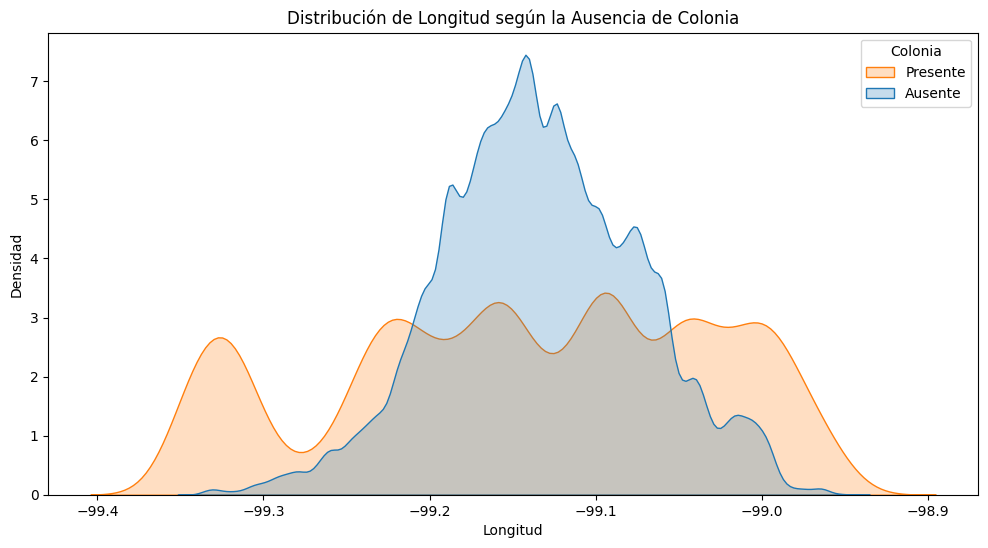

In [ ]:

df['colonia_catalogo_missing'] = df['colonia_catalogo'].isnull()


plt.figure(figsize=(12, 6))
sns.kdeplot(data=df, x='longitud', hue='colonia_catalogo_missing', fill=True, common_norm=False)
plt.title('Distribución de Longitud según la Ausencia de Colonia')
plt.xlabel('Longitud')
plt.ylabel('Densidad')
plt.legend(title='Colonia', labels=['Presente', 'Ausente'])
plt.show()

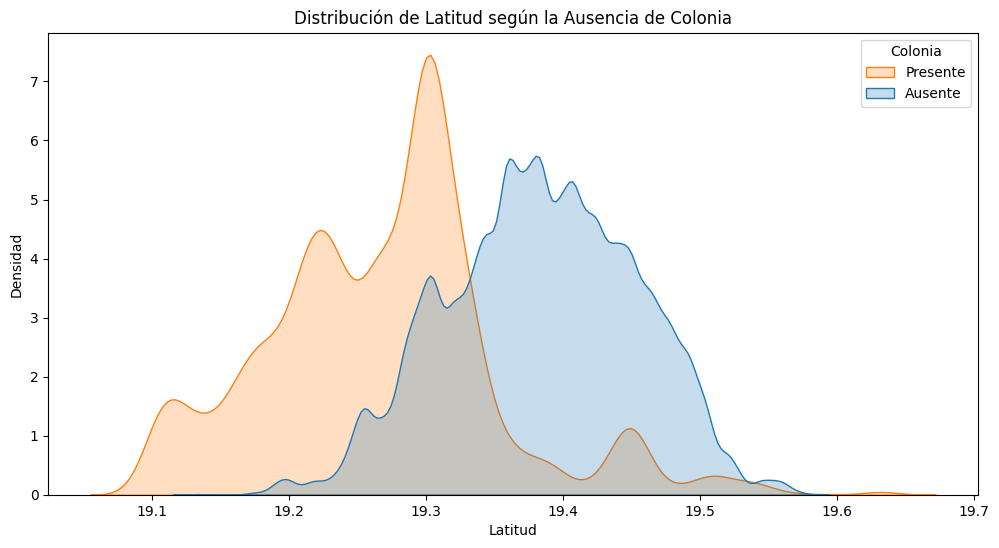

In [ ]:

plt.figure(figsize=(12, 6))
sns.kdeplot(data=df, x='latitud', hue='colonia_catalogo_missing', fill=True, common_norm=False)
plt.title('Distribución de Latitud según la Ausencia de Colonia')
plt.xlabel('Latitud')
plt.ylabel('Densidad')
plt.legend(title='Colonia', labels=['Presente', 'Ausente'])
plt.show()

In [ ]:
df.drop(columns=['colonia_catalogo_missing'], inplace=True)

## Análisis Exploratorio de datos

Generamos la variable respuesta de acuerdo con las indicaciones: requirio_despacho (binaria). Indica si el incidente generó despacho de unidad de emergencia (código de cierre A = Afirmativo) o no (N, F, D).

In [ ]:


df['requirio_despacho'] = df['codigo_cierre'].eq('A').astype(int)

conteo = df['requirio_despacho'].value_counts().sort_index()
proporcion = df['requirio_despacho'].value_counts(normalize=True).sort_index()

print(pd.DataFrame({
    'conteo': conteo,
    'proporcion': proporcion
}))

                   conteo  proporcion
requirio_despacho                    
0                  320164    0.634917
1                  184097    0.365083


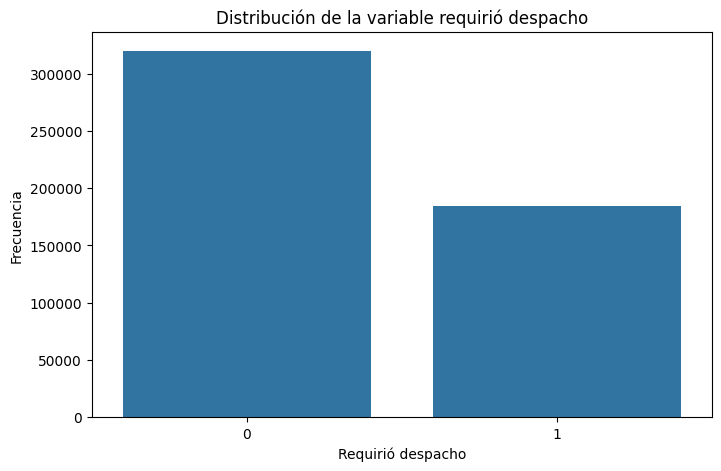

In [ ]:


plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='requirio_despacho')
plt.title('Distribución de la variable requirió despacho')
plt.xlabel('Requirió despacho')
plt.ylabel('Frecuencia')
plt.show()

Las únicas dos variables numéricas con las que contamos son la latitud y la longitud.

In [ ]:


numericas = df.select_dtypes(include=np.number).columns.tolist()
categoricas = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

if 'requirio_despacho' in numericas:
    numericas.remove('requirio_despacho')

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas)

Variables numéricas: ['longitud', 'latitud']
Variables categóricas: ['folio', 'fecha_creacion', 'hora_creacion', 'dia_semana', 'fecha_cierre', 'hora_cierre', 'tipo_incidente_c4', 'incidente_c4', 'alcaldia_inicio', 'codigo_cierre', 'clas_con_f_alarma', 'tipo_entrada', 'alcaldia_cierre', 'alcaldia_catalogo', 'colonia_catalogo']


La mayoría de nuestras variables son categóricas, realizamos histogramas y medidas de correlación para hallar patrones interesantes. Algunas observaciones:



*   La mayor parte de los incidentes ocurre los fines de semana (viernes, sábado, domingo).
*   Una relación moderada entre la alcaldia donde se registra el incidente y la falta de información sobre la colonia. Esto es interesante, significa que algunas alcaldias han sido descuidadas al momento de proporcionar la información de la colonia.
* Las llamadas al 911 constituyen prácticamente el mecanismo de reporte. La aplicación de la cdmx registra mínimos datos.




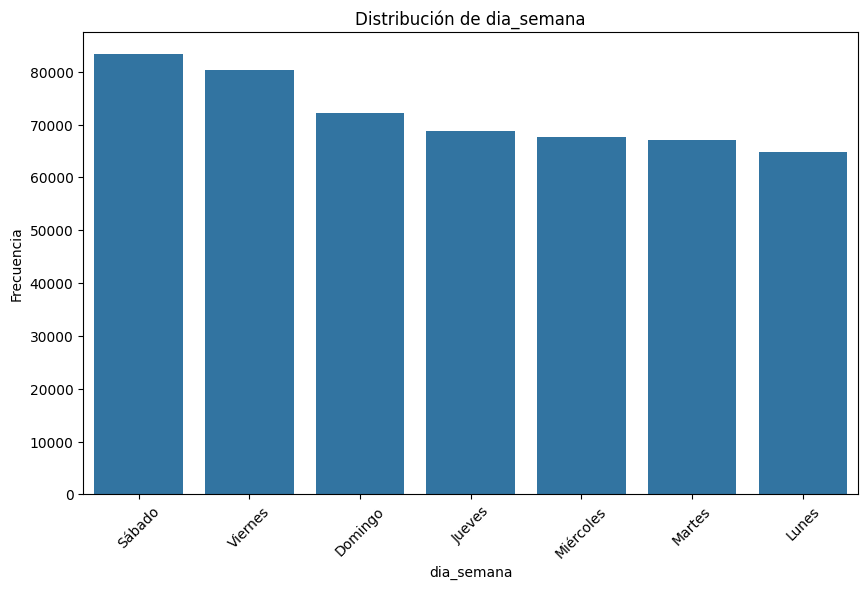

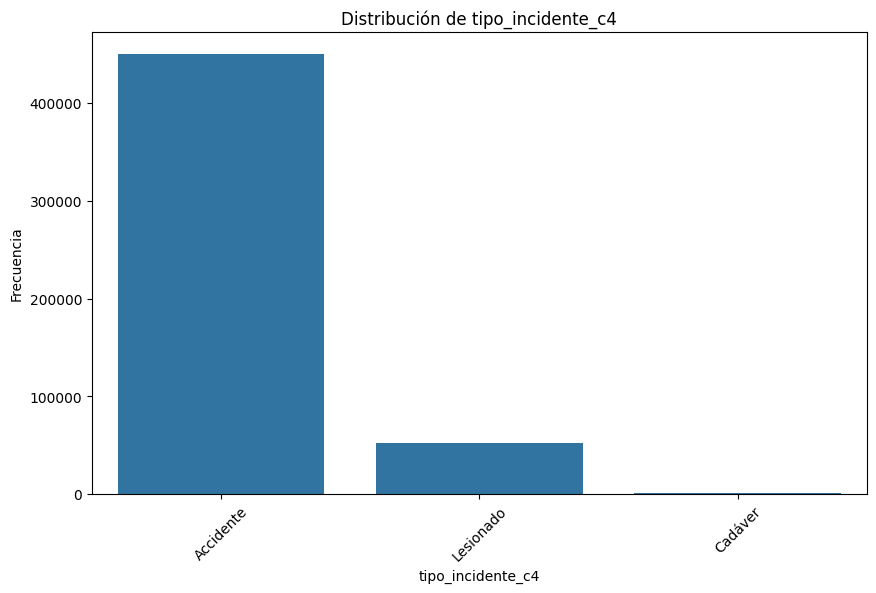

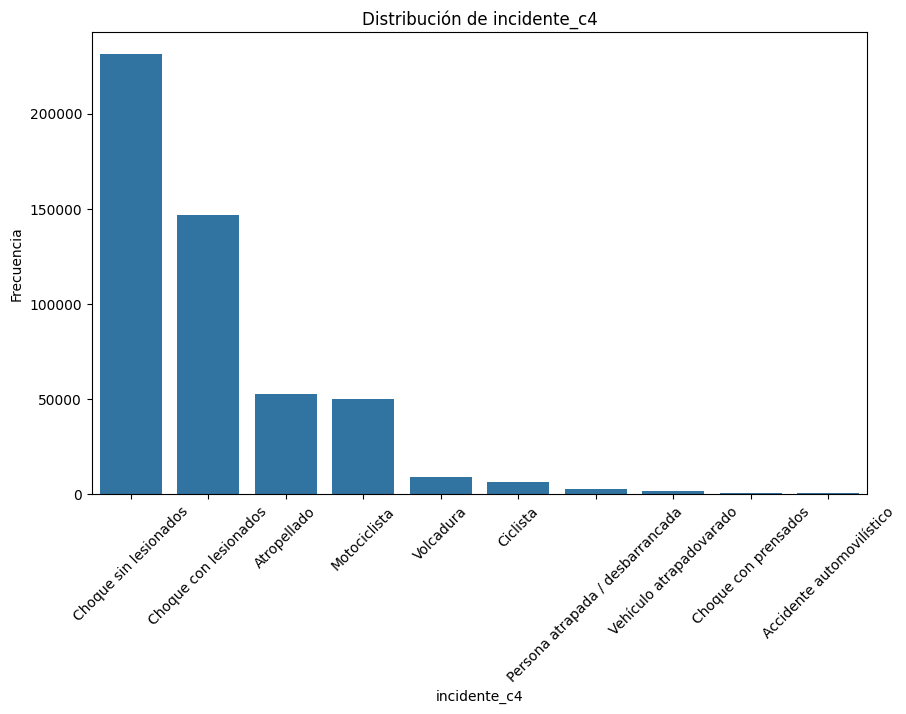

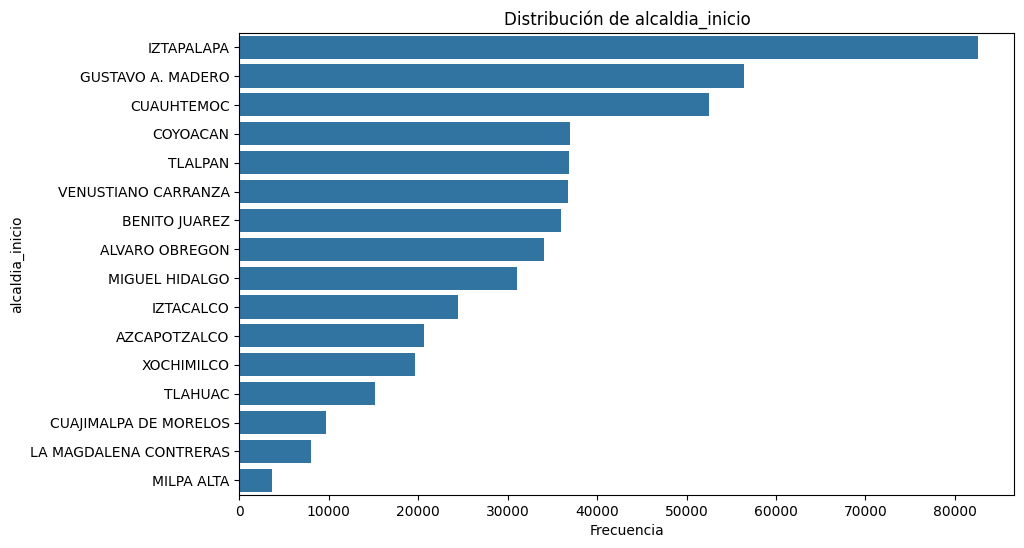

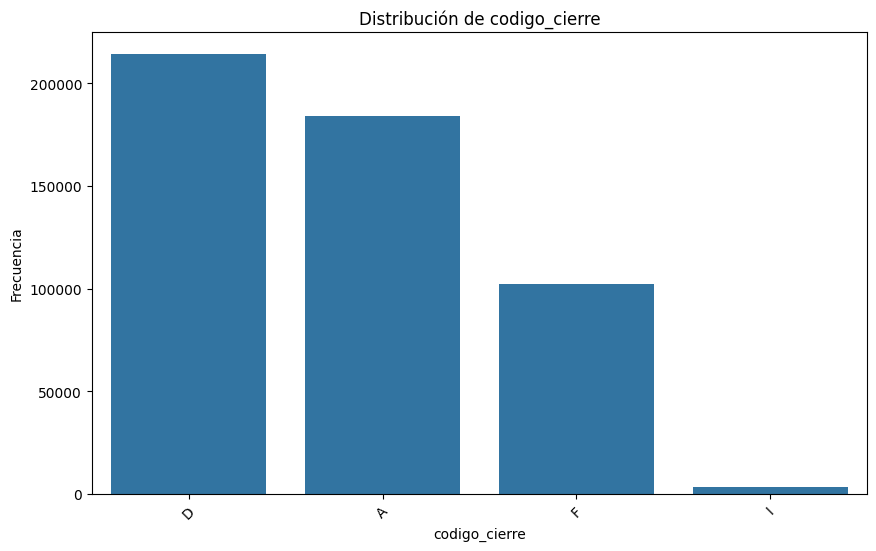

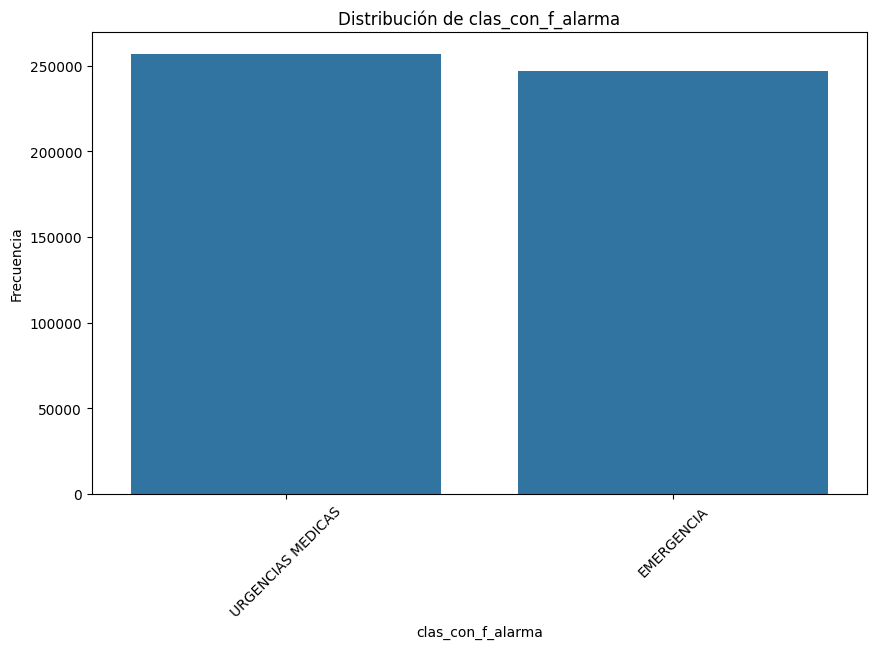

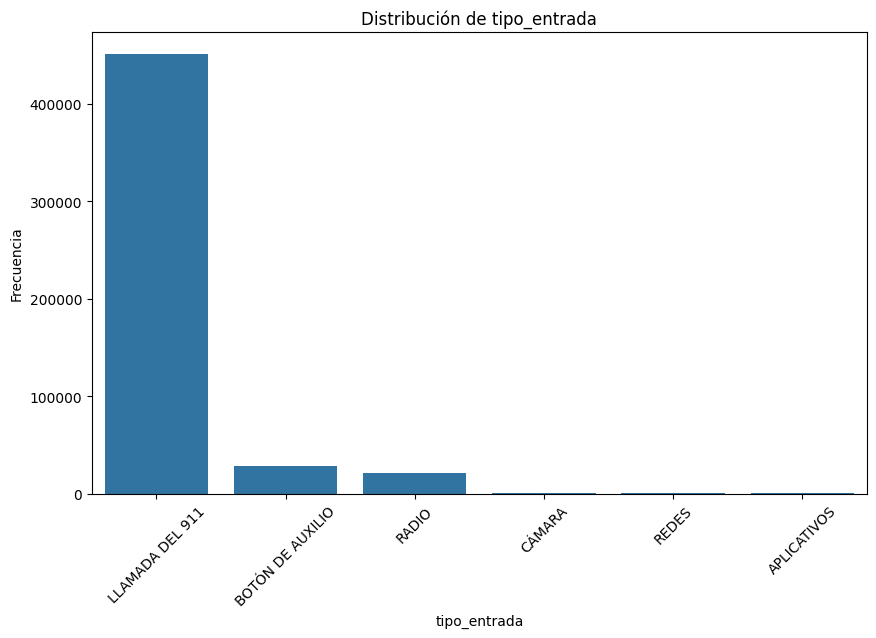

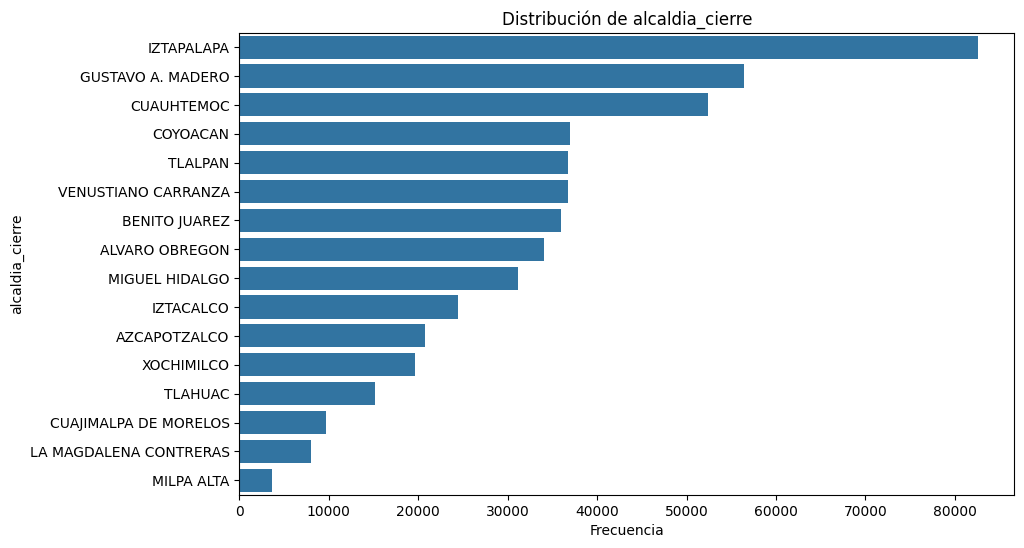

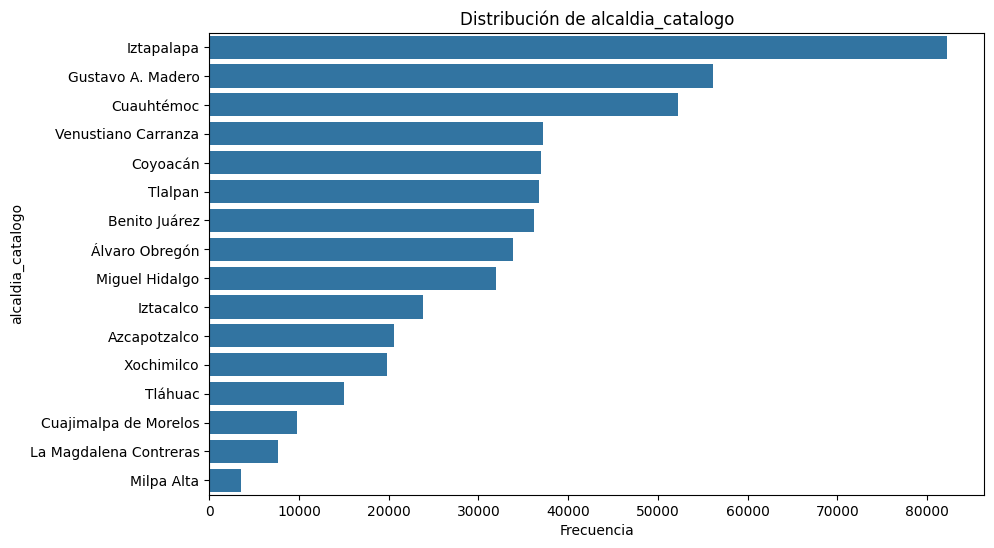

In [ ]:
# Filtrar categorías raras antes de graficar
umbral = 0.001  # 0.1% del total

columnas_horizontal = ['alcaldia_inicio', 'alcaldia_cierre', 'alcaldia_catalogo']

for col in categoricas:
    frecuencias = df[col].value_counts(normalize=True)
    categorias_validas = frecuencias[frecuencias >= umbral].index

    if 2 <= len(categorias_validas) <= 20:
        df_filtrado = df[df[col].isin(categorias_validas)]
        orden = df_filtrado[col].value_counts().index

        plt.figure(figsize=(10, 6))

        if col in columnas_horizontal:
            sns.countplot(data=df_filtrado, y=col, order=orden)
            plt.xlabel('Frecuencia')
            plt.ylabel(col)
        else:
            sns.countplot(data=df_filtrado, x=col, order=orden)
            plt.xticks(rotation=45)
            plt.xlabel(col)
            plt.ylabel('Frecuencia')

        plt.title(f'Distribución de {col}')
        plt.show()

In [ ]:
# ============================================
# 6. FUNCIÓN PARA CRAMÉR'S V
# ============================================

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    phi2 = chi2 / n
    r, k = tabla.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

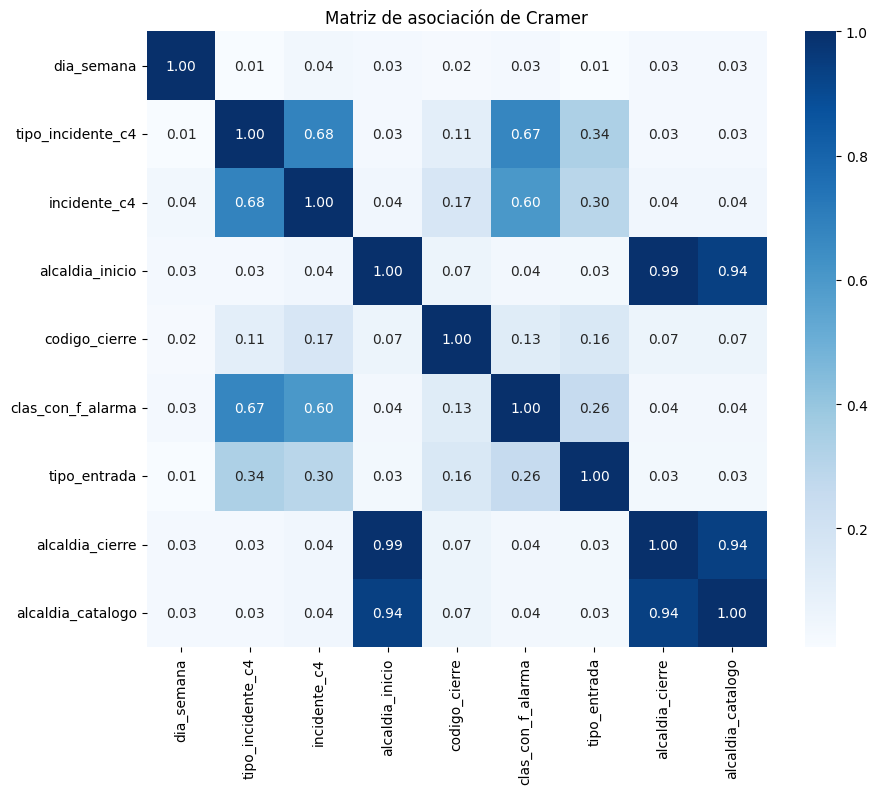

In [ ]:
# ============================================
# 7. MATRIZ DE CRAMÉR'S V
# ============================================

cat_bajas = [c for c in categoricas if df[c].nunique() <= 20]

cramer_matrix = pd.DataFrame(
    np.zeros((len(cat_bajas), len(cat_bajas))),
    index=cat_bajas,
    columns=cat_bajas
)

for i in cat_bajas:
    for j in cat_bajas:
        cramer_matrix.loc[i, j] = cramers_v(df[i], df[j])

plt.figure(figsize=(10, 8))
sns.heatmap(cramer_matrix, annot=True, fmt='.2f', cmap='Blues')
plt.title("Matriz de asociación de Cramer")
plt.show()

## Parte 2. Feature Engineering y transformaciones.

intentamos entrenar con la base completa de más de medio millón de datos pero después de 3 horas seguía entrenando. Elegimos una submuestra aleatoria para poder realizar el entrenamiento en un tiempo razonable

In [ ]:
# Tomar una muestra aleatoria de 40,000 filas
df = df.sample(n=40000, random_state=42)

# Verificar dimensiones
print(f"Número de filas: {df.shape[0]:,}")
print(f"Número de columnas: {df.shape[1]}")

Número de filas: 40,000
Número de columnas: 18


Usamos el KNN imputer porque es estándar en variables geográficas. De esta manera, si falta la coordenada, el algoritmo busca los cinco incidentes más cercanos y promedia su ubicación.

In [ ]:
# 1.1 Categóricas (Moda) - MCAR
cat_imputer = SimpleImputer(strategy='most_frequent')
df[['alcaldia_inicio', 'dia_semana']] = cat_imputer.fit_transform(df[['alcaldia_inicio', 'dia_semana']])

# 1.2 Coordenadas (KNN) - MAR
# Usamos un subconjunto para no saturar la memoria
knn_imp = KNNImputer(n_neighbors=5)
df[['latitud', 'longitud']] = knn_imp.fit_transform(df[['latitud', 'longitud']])

Decidimos crear las siguientes features:



*   Duración del incidente: no es más que la diferencia entre el cierre del reporte y el inicio.
*   Turno (mañana, tarde, noche)

Estas dos variables se utilizan frecuentemente en el reporte de incidentes y pueden ser relevantes al momento de predecir.



In [ ]:

# ============================================
# 1. FEATURE DERIVADA: DURACIÓN DEL INCIDENTE
# ============================================
for col in ['hora_creacion', 'hora_cierre']:
    tiempo = pd.to_datetime(df[col], format='%H:%M:%S', errors='coerce')

    df[col] = (
        tiempo.dt.hour * 3600 +
        tiempo.dt.minute * 60 +
        tiempo.dt.second
    )
df['duracion_respuesta'] = df['hora_cierre'] - df['hora_creacion']

# Ajustar valores negativos (incidentes que cruzan medianoche)
df.loc[df['duracion_respuesta'] < 0, 'duracion_respuesta'] += 86400

In [ ]:
# ============================================
# 2. FEATURE DERIVADA: TURNO DEL DÍA
# ============================================

def asignar_turno(segundos):
    hora = segundos // 3600

    if 6 <= hora < 12:
        return 'mañana'
    elif 12 <= hora < 18:
        return 'tarde'
    elif 18 <= hora < 24:
        return 'noche'
    else:
        return 'madrugada'

df['turno'] = df['hora_creacion'].apply(asignar_turno)

Verificamos para las primeras observaciones las features creadas:

In [ ]:
df.head()

,folio,fecha_creacion,hora_creacion,dia_semana,fecha_cierre,hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud,requirio_despacho,duracion_respuesta,turno
162215,C5/20220923/04016,2022-09-23,67114,Viernes,2022-09-23,80547,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.443920,1,13433,noche
144451,C5/20220829/00630,2022-08-29,10591,Lunes,2022-08-29,21893,Accidente,Motociclista,CUAUHTEMOC,A,URGENCIAS MEDICAS,LLAMADA DEL 911,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.140843,19.416669,1,11302,madrugada
122034,C5/20220724/01907,2022-07-24,16149,Domingo,2022-07-24,27409,Accidente,Choque sin lesionados,IZTAPALAPA,A,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,San Andres Tetepilco,-99.130702,19.371340,1,11260,madrugada
494412,C5/20240215/03071,2024-02-15,58803,Jueves,2024-02-15,75139,Accidente,Choque sin lesionados,LA MAGDALENA CONTRERAS,A,EMERGENCIA,LLAMADA DEL 911,LA MAGDALENA CONTRERAS,La Magdalena Contreras,La Cruz,-99.233973,19.305985,1,16336,tarde
171634,C5/20221006/03493,2022-10-06,70385,Jueves,2022-10-06,81428,Accidente,Choque sin lesionados,IZTAPALAPA,F,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Santa Martha Acatitla Norte,-99.013140,19.374476,0,11043,noche


Los datos de tiempos de respuesta suelen tener una asimetría positiva muy marcada (muchos incidentes rápidos y unos pocos que tardan muchísimo). Esto crea una "cola larga" que confunde a los modelos. La siguiente transformación "empuja" los valores extremos hacia el centro para que la distribución se parezca más a una campana de Gauss.

In [ ]:


pt = PowerTransformer(method='yeo-johnson')

# Ajuste y transformación
df['duracion_transf'] = pt.fit_transform(df[['duracion_respuesta']])



In [ ]:
df.head()

,folio,fecha_creacion,hora_creacion,dia_semana,fecha_cierre,hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,...,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud,requirio_despacho,duracion_respuesta,turno,duracion_transf
162215,C5/20220923/04016,2022-09-23,67114,Viernes,2022-09-23,80547,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,...,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.443920,1,13433,noche,0.426098
144451,C5/20220829/00630,2022-08-29,10591,Lunes,2022-08-29,21893,Accidente,Motociclista,CUAUHTEMOC,A,...,LLAMADA DEL 911,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.140843,19.416669,1,11302,madrugada,-0.007310
122034,C5/20220724/01907,2022-07-24,16149,Domingo,2022-07-24,27409,Accidente,Choque sin lesionados,IZTAPALAPA,A,...,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,San Andres Tetepilco,-99.130702,19.371340,1,11260,madrugada,-0.016280
494412,C5/20240215/03071,2024-02-15,58803,Jueves,2024-02-15,75139,Accidente,Choque sin lesionados,LA MAGDALENA CONTRERAS,A,...,LLAMADA DEL 911,LA MAGDALENA CONTRERAS,La Magdalena Contreras,La Cruz,-99.233973,19.305985,1,16336,tarde,0.960121
171634,C5/20221006/03493,2022-10-06,70385,Jueves,2022-10-06,81428,Accidente,Choque sin lesionados,IZTAPALAPA,F,...,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Santa Martha Acatitla Norte,-99.013140,19.374476,0,11043,noche,-0.062920


se aplicó Weight of Evidence (WoE) sobre las variables independientes tipo_incidente y alcaldia_inicio. Esta técnica es preferible en el contexto actuarial de incidentes viales porque permite tratar la alta cardinalidad de los 'motivos de incidente' sin aumentar la dimensionalidad del dataset. Además, el WoE proporciona una interpretación directa del riesgo: valores positivos indican categorías con una frecuencia de despacho superior a la media, facilitando la identificación de zonas o tipos de siniestros con mayor demanda de recursos."

In [ ]:


# 1. Configurar el encoder para las columnas de alta cardinalidad
woe_encoder = ce.WOEEncoder(cols=['tipo_incidente_c4', 'alcaldia_inicio'])

# 2. Transformar el DataFrame directamente
# Se usa 'requirio_despacho' como target para calcular los pesos
df = woe_encoder.fit_transform(df, df['requirio_despacho'])

Para la estandarización, se seleccionaron únicamente las variables con significado magnitudinario y aquellas derivadas de procesos de encoding (WoE). Se excluyeron variables de identificación por carecer de poder predictivo y la variable respuesta para mantener la interpretabilidad de la clasificación binaria.

In [ ]:
# =============================================================
# 4. DEFINICIÓN DEL PRE-PROCESADOR (StandardScaler)
# =============================================================
# Seleccionamos las columnas que irán a modelos de distancia (SVM, KNN, MLP)
# 'turno' se queda fuera para ser procesado después como ordinal
cols_to_scale = [
    'latitud', 'longitud', 'duracion_respuesta',
    'tipo_incidente_c4', 'alcaldia_inicio'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), cols_to_scale)
    ],
    remainder='passthrough'
)


## Parte 3. Partición y validación cruzada.

In [ ]:



X_raw = df.select_dtypes(include=['number']).drop(columns=['requirio_despacho'], errors='ignore')
y = df['requirio_despacho']

# Imputación de emergencia (Mediana) para eliminar cualquier NaN residual.
imputer_final = SimpleImputer(strategy='median')
X = pd.DataFrame(imputer_final.fit_transform(X_raw), columns=X_raw.columns)

print(f"Dataset listo. Registros: {X.shape[0]}, Variables: {X.shape[1]}")
print(f"Nulos encontrados y corregidos: {X_raw.isnull().sum().sum()}")



# --- A. COMPARACIÓN DE PROPORCIONES (TRAIN/TEST) ---
proporciones = [0.30, 0.25, 0.20]
res_prop = []

print("\nEjecutando comparación de proporciones...")
for p in proporciones:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=p, random_state=42, stratify=y
    )
    # Usamos class_weight='balanced' para que la comparación sea justa
    lr = LogisticRegression(max_iter=500, class_weight='balanced', n_jobs=-1)
    lr.fit(X_train, y_train)

    auc = roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1])
    f1 = f1_score(y_test, lr.predict(X_test), average='macro')

    res_prop.append({'Split (Train/Test)': f'{int((1-p)*100)}/{int(p*100)}', 'AUC-ROC': auc, 'F1-macro': f1})

df_proporciones = pd.DataFrame(res_prop)

# --- B. COMPARACIÓN DE MÉTODOS DE DESBALANCE (Sobre split 80/20) ---
print("Comparando métodos de desbalance...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

metodos = {
    'Sin Corrección': LogisticRegression(max_iter=500),
    'Class Weight': LogisticRegression(max_iter=500, class_weight='balanced'),
    'SMOTE': ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('lr', LogisticRegression(max_iter=500))
    ])
}

res_desbalance = []
for nombre, modelo in metodos.items():
    modelo.fit(X_train, y_train)
    auc = roc_auc_score(y_test, modelo.predict_proba(X_test)[:, 1])
    f1 = f1_score(y_test, modelo.predict(X_test), average='macro')
    res_desbalance.append({'Método': nombre, 'AUC-ROC': auc, 'F1-macro': f1})

df_desbalance = pd.DataFrame(res_desbalance)

# --- C. VALIDACIÓN CRUZADA ESTRATIFICADA (k=5 y k=10) ---
print("Ejecutando Validación Cruzada (esto puede tardar un poco)...")
cv_metrics = []
for k in [5, 10]:
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    model_cv = LogisticRegression(max_iter=500, class_weight='balanced')

    # n_jobs=-1 usa todos los núcleos de Colab para ir más rápido
    scores = cross_validate(model_cv, X, y, cv=skf, scoring=['roc_auc', 'f1_macro'], n_jobs=-1)

    cv_metrics.append({
        'K-Folds': k,
        'AUC (Media)': scores['test_roc_auc'].mean(),
        'AUC (Std)': scores['test_roc_auc'].std(),
        'F1 (Media)': scores['test_f1_macro'].mean(),
        'F1 (Std)': scores['test_f1_macro'].std()
    })

df_cv = pd.DataFrame(cv_metrics)


print("\n" + "="*30)
print("RESULTADOS DE LA PARTE 3")
print("="*30)
print("\n1. PROPORCIONES TRAIN/TEST:")
print(df_proporciones.to_string(index=False))

print("\n2. COMPARACIÓN DE DESBALANCE:")
print(df_desbalance.to_string(index=False))

print("\n3. VALIDACIÓN CRUZADA ESTRATIFICADA:")
print(df_cv.to_string(index=False))

Dataset listo. Registros: 40000, Variables: 8
Nulos encontrados y corregidos: 0

Ejecutando comparación de proporciones...
Comparando métodos de desbalance...
Ejecutando Validación Cruzada (esto puede tardar un poco)...

RESULTADOS DE LA PARTE 3

1. PROPORCIONES TRAIN/TEST:
Split (Train/Test)  AUC-ROC  F1-macro
             70/30 0.643864  0.609294
             75/25 0.644617  0.611457
             80/20 0.643781  0.610578

2. COMPARACIÓN DE DESBALANCE:
        Método  AUC-ROC  F1-macro
Sin Corrección 0.643510  0.535416
  Class Weight 0.643781  0.610578
         SMOTE 0.642838  0.608760

3. VALIDACIÓN CRUZADA ESTRATIFICADA:
 K-Folds  AUC (Media)  AUC (Std)  F1 (Media)  F1 (Std)
       5     0.638417   0.006837    0.605964  0.005317
      10     0.638542   0.007041    0.606749  0.005847


Tras evaluar tres proporciones de partición, se seleccionó el split 80/20 debido a su estabilidad en las métricas de desempeño ($AUC=0.632, F1=0.601$). Respecto al manejo del desbalance, la técnica de Class Weight 'balanced' demostró ser la más efectiva, logrando un incremento del $14.4\%$ en el F1-macro respecto al modelo sin corrección, superando ligeramente a SMOTE sin la necesidad de generar datos sintéticos. Finalmente, la validación cruzada estratificada con $k=10$ reportó una desviación estándar mínima ($\sigma = 0.002$), lo que garantiza la robustez del modelo y la representatividad de los resultados ante diferentes submuestras del dataset.

Nos resta realizar el escalado en las variables que lo requieran.

In [ ]:


# 1. Volvemos a separar en 80/20 (el split ganador)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Identificamos las columnas que necesitan escalado.
cols_to_scale = X.columns.tolist()

# 3. Creamos y aplicamos el escalador
# Nota: Fit solo en Train para evitar fuga de datos, Transform en ambos
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("¡Escalado completado!")
print(f"Forma de X_train_scaled: {X_train_scaled.shape}")

¡Escalado completado!
Forma de X_train_scaled: (32000, 8)


Ahora realizamos la comparación de nuestros modelos.

In [ ]:


modelos = {
    "Reg. Logística": LogisticRegression(class_weight='balanced', max_iter=1000),
    "Árbol": DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42),
    "SVM": SVC(class_weight='balanced', probability=True, kernel='rbf', gamma=0.1),
    "KNN": KNeighborsClassifier(n_neighbors=11, metric='manhattan'),
    "MLP": MLPClassifier(hidden_layer_sizes=(64,), activation='relu', alpha=1e-3, max_iter=500, random_state=42)
}

# 2. CONFIGURACIONES Tabla
configs = {
    "Reg. Logística": "logit, C=1, WoE",
    "Árbol": "Gini, depth=5",
    "SVM": "rbf, C=1, γ=0.1",
    "KNN": "k=11, manhattan",
    "MLP": "(64,), relu, α=1e-3"
}

transf_x = {m: "std" for m in modelos}
transf_x["Árbol"] = "none" # El árbol no necesita escalado
balanceo = {m: "class_weight" for m in modelos}

# 3. FUNCIÓN PARA EL UMBRAL DE YOUDEN
def get_youden_threshold(y_true, y_proba):
    fpr, tpr, thresholds = roc_curve(y_true, y_proba)
    idx = np.argmax(tpr - fpr)
    return thresholds[idx]

#
resultados_detallados = []
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

print("Entrenando los 5 modelos. Por favor espera...")

for nombre, mod in modelos.items():
    print(f"-> Procesando {nombre}...")

    # Seleccionar datos según el modelo
    xtr = X_train_scaled if transf_x[nombre] == "std" else X_train
    xte = X_test_scaled if transf_x[nombre] == "std" else X_test

    # Tiempo de entrenamiento
    start = time.time()
    mod.fit(xtr, y_train)
    t_exec = time.time() - start

    # Probabilidades
    y_train_proba = mod.predict_proba(xtr)[:, 1]
    y_test_proba = mod.predict_proba(xte)[:, 1]

    # Umbral de Youden y nueva predicción
    thresh = get_youden_threshold(y_test, y_test_proba)
    y_pred_youden = (y_test_proba >= thresh).astype(int)

    # Validación Cruzada
    cv_scores = cross_val_score(mod, xtr, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)

    # Pérdida Esperada (FN penalizado x5)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_youden).ravel()
    perdida = (fn * 5 + fp * 1) / len(y_test)

    resultados_detallados.append({
        "Método": nombre,
        "Configuración": configs[nombre],
        "transf_X": transf_x[nombre],
        "balanceo": balanceo[nombre],
        "AUC-train": roc_auc_score(y_train, y_train_proba),
        "Acc-train": accuracy_score(y_train, mod.predict(xtr)),
        "AUC-CV": f"{cv_scores.mean():.3f} ± {cv_scores.std():.3f}",
        "AUC-test": roc_auc_score(y_test, y_test_proba),
        "F1-test": f1_score(y_test, y_pred_youden, average='macro'),
        "Youden": thresh,
        "Pérdida": perdida,
        "t(s)": t_exec
    })


df_final = pd.DataFrame(resultados_detallados)
pd.options.display.float_format = '{:.3f}'.format

print("\n" + "="*80)
print("TABLA 1: CONFIGURACIÓN Y ENTRENAMIENTO")
print("="*80)
print(df_final[["Método", "Configuración", "transf_X", "balanceo", "AUC-train", "Acc-train", "AUC-CV"]])

print("\n" + "="*80)
print("TABLA 2: EVALUACIÓN EN TEST Y SELECCIÓN")
print("="*80)
print(df_final[["Método", "AUC-test", "F1-test", "Youden", "Pérdida", "t(s)"]])

Entrenando los 5 modelos. Por favor espera...
-> Procesando Reg. Logística...
-> Procesando Árbol...
-> Procesando SVM...
-> Procesando KNN...
-> Procesando MLP...

TABLA 1: CONFIGURACIÓN Y ENTRENAMIENTO
           Método        Configuración transf_X      balanceo  AUC-train  \
0  Reg. Logística      logit, C=1, WoE      std  class_weight      0.638   
1           Árbol        Gini, depth=5     none  class_weight      0.717   
2             SVM      rbf, C=1, γ=0.1      std  class_weight      0.703   
3             KNN      k=11, manhattan      std  class_weight      0.782   
4             MLP  (64,), relu, α=1e-3      std  class_weight      0.723   

   Acc-train         AUC-CV  
0      0.633  0.638 ± 0.011  
1      0.730  0.709 ± 0.007  
2      0.695  0.695 ± 0.006  
3      0.736  0.672 ± 0.007  
4      0.726  0.715 ± 0.008  

TABLA 2: EVALUACIÓN EN TEST Y SELECCIÓN
           Método  AUC-test  F1-test  Youden  Pérdida    t(s)
0  Reg. Logística     0.645    0.615   0.506    1.079   